# Global Vessel Intelligence System

## 01 - Exploratory AIS Data Analysis

### Objectives

- Load live AIS vessel position data.
- Assess data quality and completeness.
- Analyse vessel movements and speed distributions.
- Identify stationary and moving vessels.
- Visualise vessel positions around Singapore.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data" / "raw"

ais_files = sorted(
    DATA_DIR.glob("ais_positions_*.csv"),
    reverse=True
)

if not ais_files:
    raise FileNotFoundError("No AIS datasets found.")

# Select the latest non-empty dataset
for file in ais_files:

    df = pd.read_csv(
        file,
        dtype={"mmsi": str}
    )

    if not df.empty:
        latest_file = file
        break

else:
    raise ValueError("All AIS datasets are empty.")

print(f"Dataset: {latest_file.name}")
print(f"Total records: {len(df):,}")
print(f"Total columns: {df.shape[1]}")
print(f"Unique vessels: {df['mmsi'].nunique():,}")

display(df.head(10))

Dataset: ais_positions_20261126_151213.csv
Total records: 211
Total columns: 12
Unique vessels: 171


,received_at_utc,mmsi,ship_name,latitude,longitude,speed_over_ground,course_over_ground,true_heading,navigation_status,rate_of_turn,position_accuracy,message_type
0,2026-11-26T15:12:48.521370+00:00,563142000,PENGUIN REDEEM,1.227400,103.777338,0.1,208.8,117,8,0,False,PositionReport
1,2026-11-26T15:12:51.615038+00:00,563227800,SYUKUR,1.403260,104.019500,3.4,285.7,511,2,-128,True,PositionReport
2,2026-11-26T15:12:52.994502+00:00,538011485,SEAWAYS LILY,1.227592,103.798093,0.0,295.8,77,1,0,False,PositionReport
3,2026-11-26T15:12:52.994502+00:00,566135000,KOSMOS LILY,1.290498,103.949175,7.4,90.9,81,0,-128,True,PositionReport
4,2026-11-26T15:12:54.113944+00:00,563780000,SINDO 12,1.268945,103.795353,0.1,360.0,511,0,-128,False,PositionReport
5,2026-11-26T15:12:55.329088+00:00,538010780,PETROBRAS 83,1.259635,103.608935,102.3,360.0,269,3,0,False,PositionReport
6,2026-11-26T15:12:57.023671+00:00,351577000,FUTURE,1.264150,103.775583,5.9,217.0,220,0,0,False,PositionReport
7,2026-11-26T15:12:57.661171+00:00,353599000,ANNABELLA,1.184033,103.748267,0.0,177.0,89,1,0,True,PositionReport
8,2026-11-26T15:12:59.962358+00:00,563009180,NOBLE ACE TG41,1.262832,103.846523,0.3,31.5,511,0,-128,True,PositionReport
9,2026-11-26T15:13:00.742312+00:00,355008000,NAZMI C,1.263340,103.885130,0.0,147.2,31,1,-1,False,PositionReport


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211 entries, 0 to 210
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   received_at_utc     211 non-null    str    
 1   mmsi                211 non-null    str    
 2   ship_name           209 non-null    str    
 3   latitude            211 non-null    float64
 4   longitude           211 non-null    float64
 5   speed_over_ground   211 non-null    float64
 6   course_over_ground  211 non-null    float64
 7   true_heading        211 non-null    int64  
 8   navigation_status   211 non-null    int64  
 9   rate_of_turn        211 non-null    int64  
 10  position_accuracy   211 non-null    bool   
 11  message_type        211 non-null    str    
dtypes: bool(1), float64(4), int64(3), str(4)
memory usage: 32.0 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,211.0,1.254808,0.055191,1.073032,1.236468,1.262383,1.287386,1.458167
longitude,211.0,103.907429,0.082860,103.608935,103.849410,103.923420,103.955446,104.145852
speed_over_ground,211.0,2.434597,7.815771,0.000000,0.000000,0.100000,2.800000,102.300000
course_over_ground,211.0,203.758294,106.877681,0.000000,123.150000,215.500000,295.150000,360.000000
true_heading,211.0,191.094787,189.523162,0.000000,52.500000,77.000000,299.000000,511.000000
navigation_status,211.0,2.080569,3.757932,0.000000,0.000000,1.000000,1.000000,15.000000
rate_of_turn,211.0,-30.345972,64.932850,-128.000000,-128.000000,0.000000,0.000000,127.000000


In [6]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(
    missing_values.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
ship_name,2,0.95
received_at_utc,0,0.00
mmsi,0,0.00
latitude,0,0.00
longitude,0,0.00
speed_over_ground,0,0.00
course_over_ground,0,0.00
true_heading,0,0.00
navigation_status,0,0.00
rate_of_turn,0,0.00


In [7]:
df["received_at_utc"] = pd.to_datetime(
    df["received_at_utc"],
    utc=True
)

# Latest observation for each vessel
latest_vessels = (
    df.sort_values("received_at_utc")
      .drop_duplicates("mmsi", keep="last")
      .copy()
)

# AIS speed of 102.3 knots indicates unavailable data
valid_speed = latest_vessels[
    latest_vessels["speed_over_ground"].between(
        0, 102.2
    )
].copy()

summary = {
    "Total AIS Records": len(df),
    "Unique Vessels": df["mmsi"].nunique(),
    "Vessels with Valid Speed": len(valid_speed),
    "Average Speed (knots)": round(
        valid_speed["speed_over_ground"].mean(), 2
    ),
    "Maximum Speed (knots)": (
        valid_speed["speed_over_ground"].max()
    ),
    "Stationary Vessels": (
        valid_speed["speed_over_ground"] < 0.5
    ).sum(),
    "Moving Vessels": (
        valid_speed["speed_over_ground"] >= 0.5
    ).sum(),
    "Duplicate Records": df.duplicated().sum()
}

display(
    pd.DataFrame(
        summary.items(),
        columns=["Metric", "Value"]
    )
)

,Metric,Value
0,Total AIS Records,211.00
1,Unique Vessels,171.00
2,Vessels with Valid Speed,170.00
3,Average Speed (knots),1.72
4,Maximum Speed (knots),20.00
5,Stationary Vessels,125.00
6,Moving Vessels,45.00
7,Duplicate Records,0.00


In [8]:
df_clean = df.copy()

# Handle unavailable AIS values
df_clean["speed_over_ground"] = (
    df_clean["speed_over_ground"].replace(102.3, np.nan)
)

df_clean["course_over_ground"] = (
    df_clean["course_over_ground"].replace(360, np.nan)
)

df_clean["true_heading"] = (
    df_clean["true_heading"].replace(511, np.nan)
)

# Remove invalid geographical coordinates
df_clean = df_clean[
    df_clean["latitude"].between(-90, 90) &
    df_clean["longitude"].between(-180, 180)
].copy()

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

# Get the latest observation for each vessel
latest_vessels = (
    df_clean.sort_values("received_at_utc")
    .drop_duplicates("mmsi", keep="last")
    .copy()
)

print(f"Original records: {len(df):,}")
print(f"Cleaned records: {len(df_clean):,}")
print(f"Unique vessels: {len(latest_vessels):,}")
print(f"Records removed: {len(df) - len(df_clean):,}")

Original records: 211
Cleaned records: 211
Unique vessels: 171
Records removed: 0


In [9]:
def classify_movement(speed):

    if pd.isna(speed):
        return "Unknown"
    elif speed < 0.5:
        return "Stationary"
    elif speed < 5:
        return "Slow Moving"
    elif speed < 15:
        return "Cruising"
    else:
        return "High Speed"


latest_vessels["movement_status"] = (
    latest_vessels["speed_over_ground"]
    .apply(classify_movement)
)

movement_summary = (
    latest_vessels["movement_status"]
    .value_counts()
    .reset_index()
)

movement_summary.columns = [
    "Movement Status",
    "Vessel Count"
]

movement_summary["Percentage"] = (
    movement_summary["Vessel Count"]
    / len(latest_vessels) * 100
).round(2)

display(movement_summary)

,Movement Status,Vessel Count,Percentage
0,Stationary,125,73.10
1,Cruising,23,13.45
2,Slow Moving,21,12.28
3,Unknown,1,0.58
4,High Speed,1,0.58


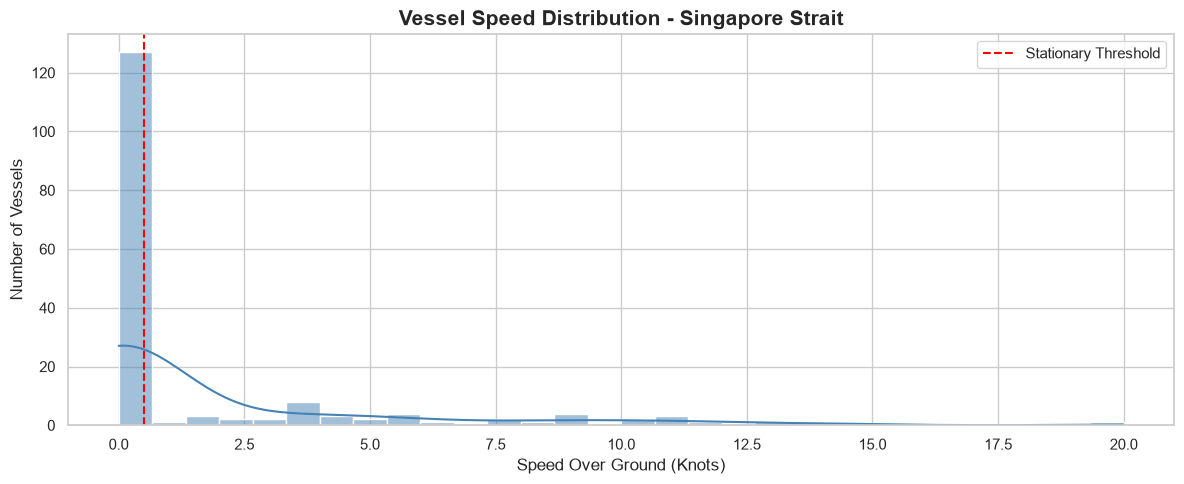

In [10]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

sns.histplot(
    data=latest_vessels,
    x="speed_over_ground",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    label="Stationary Threshold"
)

plt.title(
    "Vessel Speed Distribution - Singapore Strait",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Speed Over Ground (Knots)")
plt.ylabel("Number of Vessels")
plt.legend()
plt.tight_layout()
plt.show()

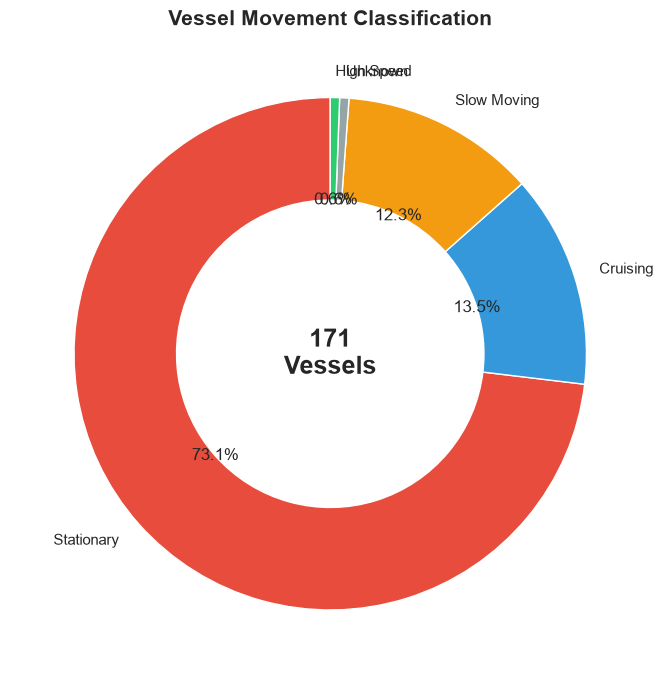

In [11]:
colors = {
    "Stationary": "#E74C3C",
    "Slow Moving": "#F39C12",
    "Cruising": "#3498DB",
    "High Speed": "#2ECC71",
    "Unknown": "#95A5A6"
}

movement_counts = (
    latest_vessels["movement_status"]
    .value_counts()
)

plt.figure(figsize=(9, 7))

plt.pie(
    movement_counts.values,
    labels=movement_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[
        colors[x] for x in movement_counts.index
    ],
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)

plt.title(
    "Vessel Movement Classification",
    fontsize=15,
    fontweight="bold"
)

plt.text(
    0, 0,
    f"{len(latest_vessels)}\nVessels",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

,Navigation Status,Vessel Count
0,At Anchor,68
1,Under Way Using Engine,68
2,Under Way Sailing,13
3,Moored,10
4,Not Defined,8
5,Restricted Manoeuvrability,2
6,Not Under Command,1
7,Other / Unknown,1


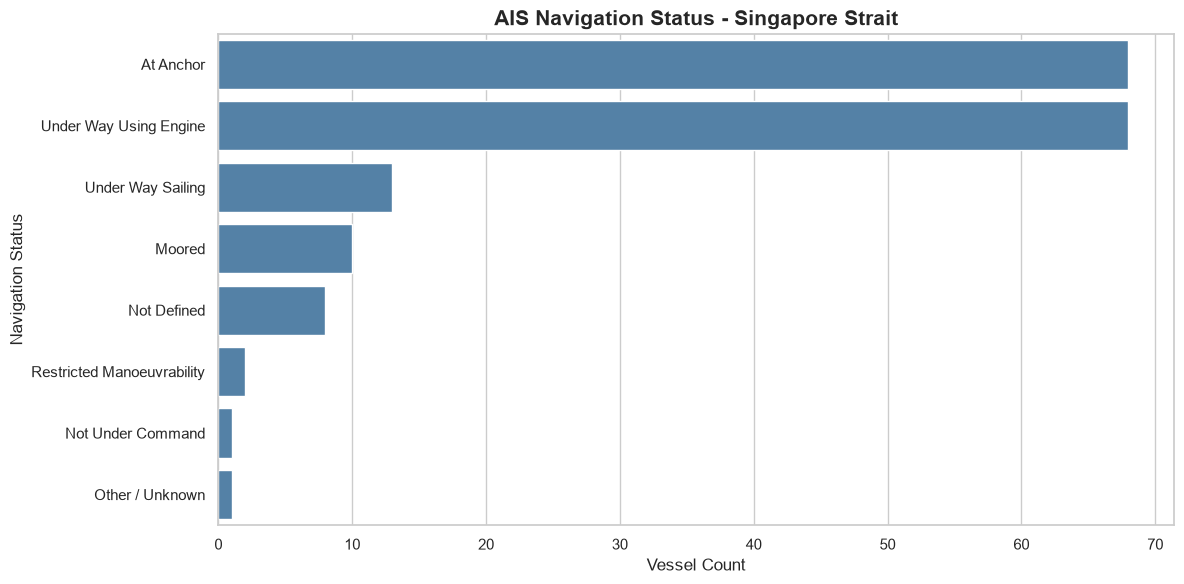

In [12]:
navigation_mapping = {
    0: "Under Way Using Engine",
    1: "At Anchor",
    2: "Not Under Command",
    3: "Restricted Manoeuvrability",
    4: "Constrained by Draught",
    5: "Moored",
    6: "Aground",
    7: "Engaged in Fishing",
    8: "Under Way Sailing",
    15: "Not Defined"
}

latest_vessels["navigation_description"] = (
    latest_vessels["navigation_status"]
    .map(navigation_mapping)
    .fillna("Other / Unknown")
)

navigation_summary = (
    latest_vessels["navigation_description"]
    .value_counts()
    .reset_index()
)

navigation_summary.columns = [
    "Navigation Status",
    "Vessel Count"
]

display(navigation_summary)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=navigation_summary,
    x="Vessel Count",
    y="Navigation Status",
    color="steelblue"
)

plt.title(
    "AIS Navigation Status - Singapore Strait",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [16]:
status_comparison = pd.crosstab(
    latest_vessels["navigation_description"],
    latest_vessels["movement_status"],
    margins=True,
    margins_name="Total"
)

display(status_comparison)

movement_status,Cruising,High Speed,Slow Moving,Stationary,Unknown,Total
navigation_description,,,,,,
At Anchor,0,0,2,66,0,68
Moored,2,1,2,5,0,10
Not Defined,0,0,2,6,0,8
Not Under Command,0,0,1,0,0,1
Other / Unknown,0,0,0,1,0,1
Restricted Manoeuvrability,0,0,0,1,1,2
Under Way Sailing,1,0,0,12,0,13
Under Way Using Engine,20,0,14,34,0,68
Total,23,1,21,125,1,171


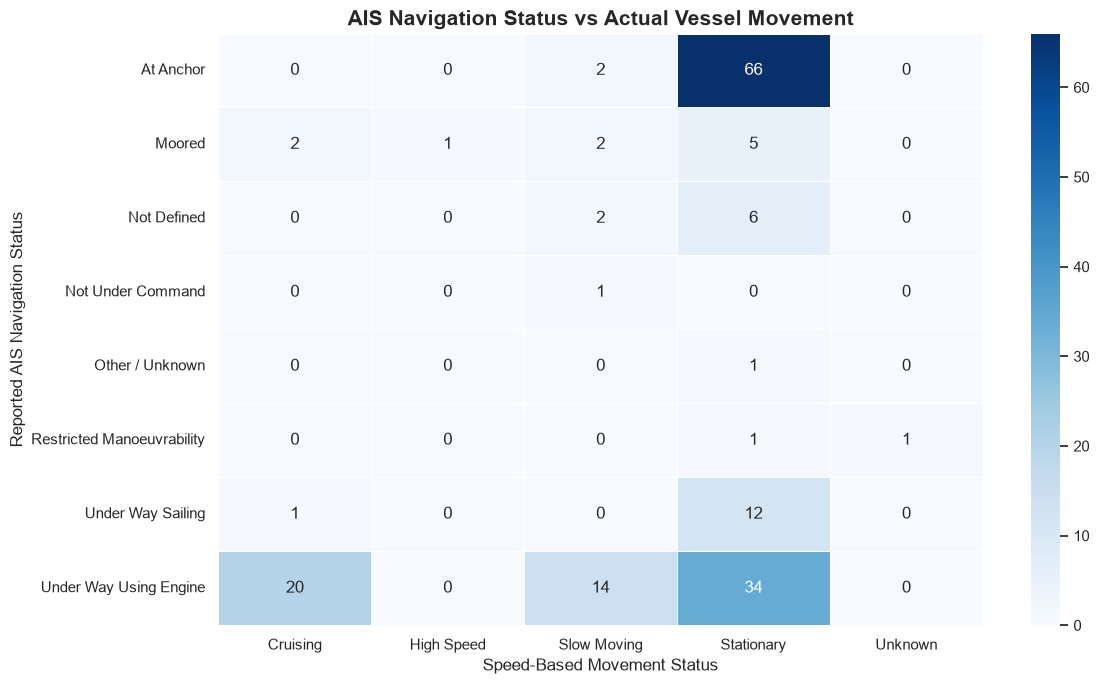

In [14]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    status_comparison.drop(
        index="Total",
        columns="Total"
    ),
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title(
    "AIS Navigation Status vs Actual Vessel Movement",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Speed-Based Movement Status")
plt.ylabel("Reported AIS Navigation Status")

plt.tight_layout()
plt.show()

In [15]:
potential_inconsistencies = latest_vessels[
    (
        latest_vessels["navigation_status"].isin([0, 8])
    ) &
    (
        latest_vessels["movement_status"] == "Stationary"
    )
].copy()

print(
    "Vessels reporting underway but stationary:",
    len(potential_inconsistencies)
)

print(
    "Percentage of observed vessels:",
    round(
        len(potential_inconsistencies)
        / len(latest_vessels) * 100,
        2
    ),
    "%"
)

display(
    potential_inconsistencies[
        [
            "mmsi",
            "ship_name",
            "speed_over_ground",
            "navigation_description",
            "movement_status"
        ]
    ]
)

Vessels reporting underway but stationary: 46
Percentage of observed vessels: 26.9 %


,mmsi,ship_name,speed_over_ground,navigation_description,movement_status
0,563142000,PENGUIN REDEEM,0.1,Under Way Sailing,Stationary
4,563780000,SINDO 12,0.1,Under Way Using Engine,Stationary
12,565081000,CALLISTO,0.0,Under Way Using Engine,Stationary
18,566849000,RESILIENCE,0.0,Under Way Using Engine,Stationary
33,525601594,TB AMADEUS 1,0.0,Under Way Using Engine,Stationary
38,412329658,LU HUANG YUAN YU 108,0.0,Under Way Sailing,Stationary
46,563024400,TICO CAPRICORN,0.0,Under Way Sailing,Stationary
56,565894000,EMINENCE,0.0,Under Way Using Engine,Stationary
59,564855000,TOLL EMPEROR,0.0,Under Way Using Engine,Stationary
63,566592000,AQUA TERRA 7,0.3,Under Way Using Engine,Stationary


In [17]:
def assess_navigation_consistency(row):

    nav = row["navigation_status"]
    speed = row["speed_over_ground"]

    if pd.isna(speed) or pd.isna(nav):
        return "Insufficient Data"

    if nav in [0, 8] and speed < 0.5:
        return "Underway but Stationary"

    if nav == 1 and speed >= 0.5:
        return "Anchored but Moving"

    if nav == 5 and speed >= 0.5:
        return "Moored but Moving"

    if nav in [0, 1, 5, 8]:
        return "No Flag"

    return "Not Assessed"


latest_vessels["data_quality_flag"] = (
    latest_vessels.apply(
        assess_navigation_consistency,
        axis=1
    )
)

quality_summary = (
    latest_vessels["data_quality_flag"]
    .value_counts()
    .reset_index()
)

quality_summary.columns = [
    "Data Quality Flag",
    "Vessel Count"
]

quality_summary["Percentage"] = (
    quality_summary["Vessel Count"]
    / len(latest_vessels) * 100
).round(2)

display(quality_summary)

,Data Quality Flag,Vessel Count,Percentage
0,No Flag,106,61.99
1,Underway but Stationary,46,26.90
2,Not Assessed,11,6.43
3,Moored but Moving,5,2.92
4,Anchored but Moving,2,1.17
5,Insufficient Data,1,0.58


### Key Findings - AIS Navigation Status Validation

The initial AIS dataset contains 211 position reports
covering 171 unique vessels in the Singapore Strait.

Key observations:

- 73.10% of observed vessels were stationary based
  on reported speed over ground.
- 46 vessels reported an underway navigation status
  despite travelling below 0.5 knots.
- 5 vessels reported a moored status while moving.
- 2 vessels reported an anchored status while moving.
- A total of 53 vessels (30.99%) triggered preliminary
  navigation consistency flags.

### Business Implications

Reliance on reported AIS navigation status alone may
produce misleading vessel activity classifications,
port congestion estimates and operational insights.

Combining vessel speed, navigation status, geographical
position and historical movement patterns may improve
the reliability of maritime intelligence.

### Limitations

The analysis is based on a five-minute AIS snapshot.
Flagged observations represent potential inconsistencies
rather than confirmed reporting errors.

Historical vessel trajectories and port geofences
are required for further validation.

### Interactive vessel tracking map 

In [32]:
import folium
import html

from folium.plugins import (
    Fullscreen,
    MousePosition,
    MiniMap,
    MeasureControl
)

# Initialise map
vessel_map = folium.Map(
    location=[1.25, 103.85],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# Vessel movement colours
movement_colors = {
    "Stationary": "#E74C3C",
    "Slow Moving": "#F39C12",
    "Cruising": "#3498DB",
    "High Speed": "#2ECC71",
    "Unknown": "#95A5A6"
}

# Create separate layers
movement_layers = {}

for status in movement_colors:

    movement_layers[status] = folium.FeatureGroup(
        name=status
    ).add_to(vessel_map)

# Add individual vessels
for _, vessel in latest_vessels.iterrows():

    status = vessel["movement_status"]

    color = movement_colors.get(
        status, "#95A5A6"
    )

    ship_name = html.escape(
        str(vessel["ship_name"])
    )

    if ship_name in ["", "nan", "None"]:
        ship_name = "Unknown Vessel"

    speed = vessel["speed_over_ground"]

    speed_display = (
        f"{speed:.1f} knots"
        if pd.notna(speed)
        else "Unavailable"
    )

    popup_content = f"""
    <div style="width:240px">
        <h4>{ship_name}</h4>
        <hr>
        <b>MMSI:</b> {vessel['mmsi']}<br>
        <b>Speed:</b> {speed_display}<br>
        <b>Course:</b> {vessel['course_over_ground']}<br>
        <b>Heading:</b> {vessel['true_heading']}<br>
        <b>Movement:</b> {status}<br>
        <b>Navigation:</b>
        {vessel['navigation_description']}<br>
        <b>Latitude:</b> {vessel['latitude']:.5f}<br>
        <b>Longitude:</b> {vessel['longitude']:.5f}<br>
        <b>Received (UTC):</b>
        {vessel['received_at_utc']}
    </div>
    """

    folium.CircleMarker(
        location=[
            vessel["latitude"],
            vessel["longitude"]
        ],
        radius=3,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.75,
        weight=0.5,
        tooltip=f"{ship_name} | {speed_display}",
        popup=folium.Popup(
            popup_content,
            max_width=300
        )
    ).add_to(movement_layers[status])

# Interactive map controls
Fullscreen().add_to(vessel_map)

MousePosition().add_to(vessel_map)

MiniMap(
    toggle_display=True
).add_to(vessel_map)

MeasureControl().add_to(vessel_map)

folium.LayerControl(
    collapsed=False
).add_to(vessel_map)

display(vessel_map)

In [33]:
legend_html = """
<div style="
    position: fixed;
    bottom: 40px;
    left: 40px;
    width: 230px;
    z-index: 9999;
    background-color: #17212B;
    color: white;
    padding: 15px;
    border: 1px solid #52616B;
    border-radius: 8px;
    font-size: 13px;
">
    <h4 style="margin-top:0;">
        Vessel Movement Status
    </h4>

    <span style="color:#E74C3C;">●</span>
    Stationary<br>

    <span style="color:#F39C12;">●</span>
    Slow Moving<br>

    <span style="color:#3498DB;">●</span>
    Cruising<br>

    <span style="color:#2ECC71;">●</span>
    High Speed<br>

    <span style="color:#95A5A6;">●</span>
    Unknown<br>

    <hr>

    <small>
        Global Vessel Intelligence System<br>
        Source: AISStream<br>
        Latest collected snapshot
    </small>
</div>
"""

vessel_map.get_root().html.add_child(
    folium.Element(legend_html)
)

display(vessel_map)

In [34]:
from folium.plugins import HeatMap

density_map = folium.Map(
    location=[1.25, 103.85],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

heat_data = (
    latest_vessels[
        ["latitude", "longitude"]
    ]
    .dropna()
    .values
    .tolist()
)

HeatMap(
    heat_data,
    radius=18,
    blur=15,
    min_opacity=0.3,
    gradient={
        0.2: "blue",
        0.4: "cyan",
        0.6: "lime",
        0.8: "yellow",
        1.0: "red"
    }
).add_to(density_map)

Fullscreen().add_to(density_map)

display(density_map)

In [35]:
MAP_DIR = BASE_DIR / "reports" / "maps"

MAP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

vessel_map.save(
    str(MAP_DIR / "singapore_vessel_tracking.html")
)

density_map.save(
    str(MAP_DIR / "singapore_vessel_density.html")
)

print("Interactive maps exported successfully.")

for file in MAP_DIR.glob("*.html"):
    print(file.name)

Interactive maps exported successfully.
singapore_vessel_density.html
singapore_vessel_tracking.html
